# Extreme Weather in a Warming World
### Trends in Frequency, Seasonality, and Economic Impact of U.S. Severe Weather Events, 1996–2024

Whether severe weather in the United States has gotten worse as the climate has warmed sounds like a simple yes-or-no question, but the answer depends on three less-obvious choices: which events you decide to count, what window you study, and which temperature record you compare them against. This project takes one specific cut at it. Using NOAA's Storm Events Database from 1996 — when its event-type coverage stabilized — through 2024, paired with the ERSSTv5 sea-surface-temperature reconstruction over the U.S.-adjacent ocean basins, I test three hypotheses.

The first is that the annual count of severe-weather events has risen significantly across the period.
The second is that the seasonal distribution of those events has shifted, which would show up as a change in how event totals are spread across the twelve months of the year. 
The third, and the one I expected to be the cleanest test, is that year-to-year fluctuations in U.S.-adjacent SST anomalies should track year-to-year fluctuations in event counts.

Both data sources are pulled programmatically inside the notebook, so the analysis re-runs end-to-end on a clean machine. The Storm Events files are gzipped, one per year, from the NCEI bulk directory; ERSSTv5 is a single monthly netCDF from PSL. Cleaning the storm data is most of the work — the raw `EVENT_TYPE` strings are inconsistent across years, damages are recorded as text like "1.50M" rather than numerically, and dates are split across two integer columns. The SST processing is straightforward in xarray: subtract a 1991–2020 monthly climatology, area-weight the U.S.-adjacent box, and reduce to annual means. Statistical tests use `scipy.stats` throughout.

The notebook produces seven figures: one map of background SST change to anchor the climate signal, and six analysis figures addressing the three hypotheses.

In [1]:
# === Fix broken PROJ_LIB on shared servers (Pangeo, JupyterHub, etc.) ===
import os
os.environ.pop('PROJ_LIB', None)
os.environ.pop('PROJ_DATA', None)
try:
    import pyproj
    os.environ['PROJ_LIB']  = pyproj.datadir.get_data_dir()
    os.environ['PROJ_DATA'] = pyproj.datadir.get_data_dir()
except ImportError:
    pass
# === Imports ===
# Standard library
import os, re, gzip, io
import urllib.request
from html.parser import HTMLParser
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Scientific stack
import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats

# Plotting
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle
import seaborn as sns

# Geographic plotting
import geopandas as gpd

# === Aesthetic configuration ===
plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 200,
    'savefig.bbox': 'tight',
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
    'legend.frameon': False,
})
sns.set_palette('Set2')
np.random.seed(42)

# === Local data cache ===
DATA_DIR = Path('./data');           DATA_DIR.mkdir(exist_ok=True)
STORM_DIR = DATA_DIR / 'storm_events'; STORM_DIR.mkdir(exist_ok=True)
FIG_DIR = Path('./figures');         FIG_DIR.mkdir(exist_ok=True)

print('Environment ready.')
print(f'  numpy  {np.__version__}')
print(f'  pandas {pd.__version__}')
print(f'  xarray {xr.__version__}')
print(f'  geopandas {gpd.__version__}')


Environment ready.
  numpy  1.26.4
  pandas 2.3.3
  xarray 2025.6.1
  geopandas 0.14.4


## 1 · Data Acquisition

NOAA appends a creation-date suffix to every Storm Events filename — for example `d2020_c20240620.csv.gz` — and reissues files when the underlying records are corrected. There is no clean URL convention to download by year, so I scrape the directory listing, regex out the year and creation date from each filename, and keep the most recently dated file for each year. This avoids hard-coding URLs that would silently break the next time NOAA reissues anything.

In [2]:
STORM_BASE_URL = "https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/"
START_YEAR, END_YEAR = 1996, 2024   # 1996 is when full event-type coverage begins

class _LinkParser(HTMLParser):
    def __init__(self):
        super().__init__(); self.links = []
    def handle_starttag(self, tag, attrs):
        if tag == 'a':
            for k, v in attrs:
                if k == 'href': self.links.append(v)

# NOAA NCEI sometimes blocks the default urllib User-Agent. Use a real one.
USER_AGENT = 'Mozilla/5.0 (compatible; ClimateResearch/1.0; Python urllib)'
def _open(url, timeout=60):
    req = urllib.request.Request(url, headers={'User-Agent': USER_AGENT})
    return urllib.request.urlopen(req, timeout=timeout)

def list_storm_files():
    """Return {year: filename} mapping for the Storm Events detail files."""
    with _open(STORM_BASE_URL) as r:
        html = r.read().decode('utf-8', errors='ignore')
    p = _LinkParser(); p.feed(html)
    out = {}
    for href in p.links:
        m = re.match(r'StormEvents_details-ftp_v1\.0_d(\d{4})_c\d{8}\.csv\.gz$', href)
        if m:
            year = int(m.group(1))
            # Keep most recently revised file for each year (lex order = chrono order)
            if year not in out or href > out[year]:
                out[year] = href
    return out

def download(url, dest, force=False):
    """Cached download with User-Agent. Returns dest Path."""
    if dest.exists() and not force:
        return dest
    print(f'  Downloading {dest.name} ...', end=' ', flush=True)
    with _open(url, timeout=600) as r, open(dest, 'wb') as f:
        while True:
            chunk = r.read(1 << 20)        # 1-MiB chunks
            if not chunk: break
            f.write(chunk)
    print(f'({dest.stat().st_size/1e6:.1f} MB)')
    return dest

print('Discovering Storm Events files...')
storm_files = list_storm_files()
years = sorted(y for y in storm_files if START_YEAR <= y <= END_YEAR)
print(f'Found {len(years)} files for years {years[0]}–{years[-1]}')

print('\nDownloading Storm Events files (cached locally on subsequent runs):')
for y in years:
    download(STORM_BASE_URL + storm_files[y], STORM_DIR / storm_files[y])
print('\nStorm Events data ready.')


Discovering Storm Events files...
Found 29 files for years 1996–2024


Storm Events data ready.


In [3]:
# Download ERSSTv5 monthly mean SST netCDF
SST_URL = "https://downloads.psl.noaa.gov/Datasets/noaa.ersst.v5/sst.mnmean.nc"
SST_LOCAL = DATA_DIR / 'sst.mnmean.nc'
print('Downloading ERSSTv5 monthly mean SST (~70 MB) ...')
download(SST_URL, SST_LOCAL)
print('ERSSTv5 data ready.')


ERSSTv5 data ready.


## 2 · Loading and Cleaning the Storm Events Data

Each yearly CSV has hundreds of thousands of rows and around fifty columns. I keep eight. Two pieces of cleaning matter for the rest of the analysis.

The damage columns store strings like `"1.50M"`, `"250K"`, or `"3B"` rather than numbers, so a small parser converts them to floats by stripping the suffix and applying the appropriate multiplier. The event-type column contains more than fifty distinct values, many of which are near-duplicates: `Hurricane` versus `Hurricane (Typhoon)`, `Marine Thunderstorm Wind` versus `Thunderstorm Wind`, and so on. I collapse them into nine working categories — Tornado, Flood, Hail, Severe Wind, Heat / Drought, Winter / Cold, Tropical Cyclone, Lightning, and Wildfire — plus a residual `Other` so that anything I haven't explicitly mapped still appears in totals rather than being silently dropped. The full mapping is in the dictionary below.

In [4]:
USEFUL = ['BEGIN_YEARMONTH', 'BEGIN_DAY', 'STATE', 'EVENT_TYPE',
          'DAMAGE_PROPERTY', 'DAMAGE_CROPS',
          'INJURIES_DIRECT', 'DEATHS_DIRECT']

# --- Damage-string parser -----------------------------------------------------
_MULT = {'H': 1e2, 'K': 1e3, 'M': 1e6, 'B': 1e9, 'T': 1e12}
def parse_damage(s):
    """Convert e.g. '1.50M', '250K', '3B' to float USD."""
    if pd.isna(s): return 0.0
    s = str(s).strip().upper()
    if not s or s == '0': return 0.0
    if s[-1] in _MULT:
        try: return float(s[:-1]) * _MULT[s[-1]]
        except ValueError: return 0.0
    try: return float(s)
    except ValueError: return 0.0

# --- Category mapping ---------------------------------------------------------
CATEGORY_MAP = {
    'Tornado'         : ['Tornado', 'Funnel Cloud', 'Waterspout'],
    'Flood'           : ['Flood', 'Flash Flood', 'Coastal Flood', 'Lakeshore Flood', 'Heavy Rain'],
    'Hail'            : ['Hail', 'Marine Hail'],
    'Severe Wind'     : ['Thunderstorm Wind', 'High Wind', 'Strong Wind',
                         'Marine Thunderstorm Wind', 'Marine High Wind', 'Marine Strong Wind'],
    'Heat / Drought'  : ['Heat', 'Excessive Heat', 'Drought'],
    'Winter / Cold'   : ['Cold/Wind Chill', 'Extreme Cold/Wind Chill', 'Winter Storm',
                         'Winter Weather', 'Heavy Snow', 'Blizzard', 'Ice Storm',
                         'Sleet', 'Frost/Freeze', 'Lake-Effect Snow'],
    'Tropical Cyclone': ['Hurricane', 'Hurricane (Typhoon)', 'Tropical Storm',
                         'Tropical Depression', 'Storm Surge/Tide'],
    'Lightning'       : ['Lightning'],
    'Wildfire'        : ['Wildfire'],
}
EVENT_TO_CAT = {ev: cat for cat, evs in CATEGORY_MAP.items() for ev in evs}
def to_category(ev): return EVENT_TO_CAT.get(ev, 'Other')

# --- Per-year loader ----------------------------------------------------------
def load_year(path):
    df = pd.read_csv(path, compression='gzip', usecols=USEFUL,
                     low_memory=False, encoding='latin-1')
    # Build a proper timestamp from YEARMONTH + DAY
    yyyymm = df['BEGIN_YEARMONTH'].astype('Int64').astype(str).str.zfill(6)
    dd     = df['BEGIN_DAY'].astype('Int64').astype(str).str.zfill(2)
    df['date']  = pd.to_datetime(yyyymm + dd, format='%Y%m%d', errors='coerce')
    df['year']  = df['date'].dt.year
    df['month'] = df['date'].dt.month
    df['damage_property_usd'] = df['DAMAGE_PROPERTY'].apply(parse_damage)
    df['damage_crops_usd']    = df['DAMAGE_CROPS'].apply(parse_damage)
    df['damage_total_usd']    = df['damage_property_usd'] + df['damage_crops_usd']
    df['category'] = df['EVENT_TYPE'].apply(to_category)
    return df.dropna(subset=['date'])

print('Loading and cleaning Storm Events files...')
frames = [load_year(STORM_DIR / storm_files[y]) for y in years]
events = pd.concat(frames, ignore_index=True)
del frames
# Ensure all years lie within the analysis window (occasional stragglers exist)
events = events[(events['year'] >= START_YEAR) & (events['year'] <= END_YEAR)].copy()
events['STATE'] = events['STATE'].str.title()

print(f'Total events {START_YEAR}–{END_YEAR}: {len(events):,}')
print(f'Categories: {sorted(events["category"].unique())}')
events.head()


Loading and cleaning Storm Events files...
Total events 1996–2024: 1,708,370
Categories: ['Flood', 'Hail', 'Heat / Drought', 'Lightning', 'Other', 'Severe Wind', 'Tornado', 'Tropical Cyclone', 'Wildfire', 'Winter / Cold']


,BEGIN_YEARMONTH,BEGIN_DAY,STATE,EVENT_TYPE,INJURIES_DIRECT,DEATHS_DIRECT,DAMAGE_PROPERTY,DAMAGE_CROPS,date,year,month,damage_property_usd,damage_crops_usd,damage_total_usd,category
0,199610,29,Illinois,High Wind,0,0,NaN,NaN,1996-10-29,1996,10,0.0,0.0,0.0,Severe Wind
1,199610,21,Oklahoma,Flash Flood,0,0,NaN,NaN,1996-10-21,1996,10,0.0,0.0,0.0,Flood
2,199610,20,Oklahoma,Hail,0,0,NaN,NaN,1996-10-20,1996,10,0.0,0.0,0.0,Hail
3,199601,23,California,Winter Storm,0,0,NaN,NaN,1996-01-23,1996,1,0.0,0.0,0.0,Winter / Cold
4,199601,17,Minnesota,Blizzard,0,0,NaN,NaN,1996-01-17,1996,1,0.0,0.0,0.0,Winter / Cold


## 3 · Processing ERSSTv5 with Xarray

Three steps. First, build a monthly climatology by grouping the SST cube by calendar month and averaging over the WMO-standard 1991–2020 window. Second, subtract that climatology from the full record to get monthly anomalies. Third, slice out the U.S.-adjacent box (20°–50°N, 130°W–60°W), area-weight by the cosine of latitude — because the grid cells are equal in degrees but not in physical area — and reduce to annual means.

The area-weighting formula is

$$\overline{T}(t) \;=\; \frac{\sum_{i,j} w_{ij}\,T_{ij}(t)}{\sum_{i,j} w_{ij}}, \qquad w_{ij} = \cos(\varphi_i),$$

with $\varphi_i$ the latitude of cell $i$. This is standard but worth writing out, because forgetting the $\cos\varphi$ factor on a global grid biases the mean cold by a non-trivial amount.

One implementation snag worth flagging. ERSSTv5 stores latitude in descending order (88°N down to −88°N), so `xarray.sel(lat=slice(20, 50))` returns an empty selection — the slice has to match the axis direction, and in this case that means writing `slice(50, 20)`. This caught me out the first time I ran the analysis, and I only noticed because every downstream SST anomaly came out as `NaN`.

In [5]:
ds = xr.open_dataset(SST_LOCAL)
sst = ds['sst']                       # (time, lat, lon)
print(sst)


<xarray.DataArray 'sst' (time: 2068, lat: 89, lon: 180)> Size: 133MB
[33129360 values with dtype=float32]
Coordinates:
  * lat      (lat) float32 356B 88.0 86.0 84.0 82.0 ... -82.0 -84.0 -86.0 -88.0
  * lon      (lon) float32 720B 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
  * time     (time) datetime64[ns] 17kB 1854-01-01 1854-02-01 ... 2026-04-01
Attributes:
    long_name:     Monthly Means of Sea Surface Temperature
    units:         degC
    var_desc:      Sea Surface Temperature
    level_desc:    Surface
    statistic:     Mean
    dataset:       NOAA Extended Reconstructed SST V5
    parent_stat:   Individual Values
    actual_range:  [-1.8     42.32636]
    valid_range:   [-1.8 45. ]


In [6]:
# 1. Monthly climatology (1991–2020 WMO baseline)
clim = (sst.sel(time=slice('1991-01-01', '2020-12-31'))
            .groupby('time.month').mean('time'))

# 2. Monthly anomalies
sst_anom = sst.groupby('time.month') - clim

# 3. U.S.-adjacent box (lat 20–50N, lon 230–300 in 0–360 convention = 130W–60W)
us_box = sst_anom.sel(lat=slice(50, 20), lon=slice(230, 300))
weights = np.cos(np.deg2rad(us_box['lat'])); weights.name = 'weights'
us_anom_monthly = us_box.weighted(weights).mean(['lat', 'lon'])

# 4. Annual mean
us_anom_annual = us_anom_monthly.groupby('time.year').mean('time')
us_anom_annual_study = us_anom_annual.sel(year=slice(START_YEAR, END_YEAR))

print('Area-weighted annual SST anomaly for the U.S.-adjacent box (°C):')
print(us_anom_annual_study.to_pandas().round(3).to_string())

Area-weighted annual SST anomaly for the U.S.-adjacent box (°C):
year
1996   -0.408
1997   -0.024
1998   -0.022
1999   -0.440
2000   -0.221
2001   -0.336
2002   -0.170
2003   -0.033
2004   -0.082
2005   -0.066
2006   -0.043
2007   -0.253
2008   -0.361
2009   -0.136
2010   -0.290
2011   -0.314
2012    0.054
2013   -0.055
2014    0.470
2015    0.913
2016    0.739
2017    0.524
2018    0.472
2019    0.408
2020    0.495
2021    0.271
2022    0.366
2023    0.449
2024    0.503


### Figure 1 · Where has the ocean warmed?

Before doing any event analysis, it's worth checking that the temperature signal we're going to correlate against is in fact present and spatially coherent. The map below shows the change in mean SST between the first decade of the study (1996–2005) and the most recent (2015–2024). The black box marks the area-weighting region used in the rest of the analysis. The pattern is what a textbook would predict — broad warming over most of the global ocean with a few cold spots in the subpolar North Atlantic and Southern Ocean — which is reassuring before going any further.

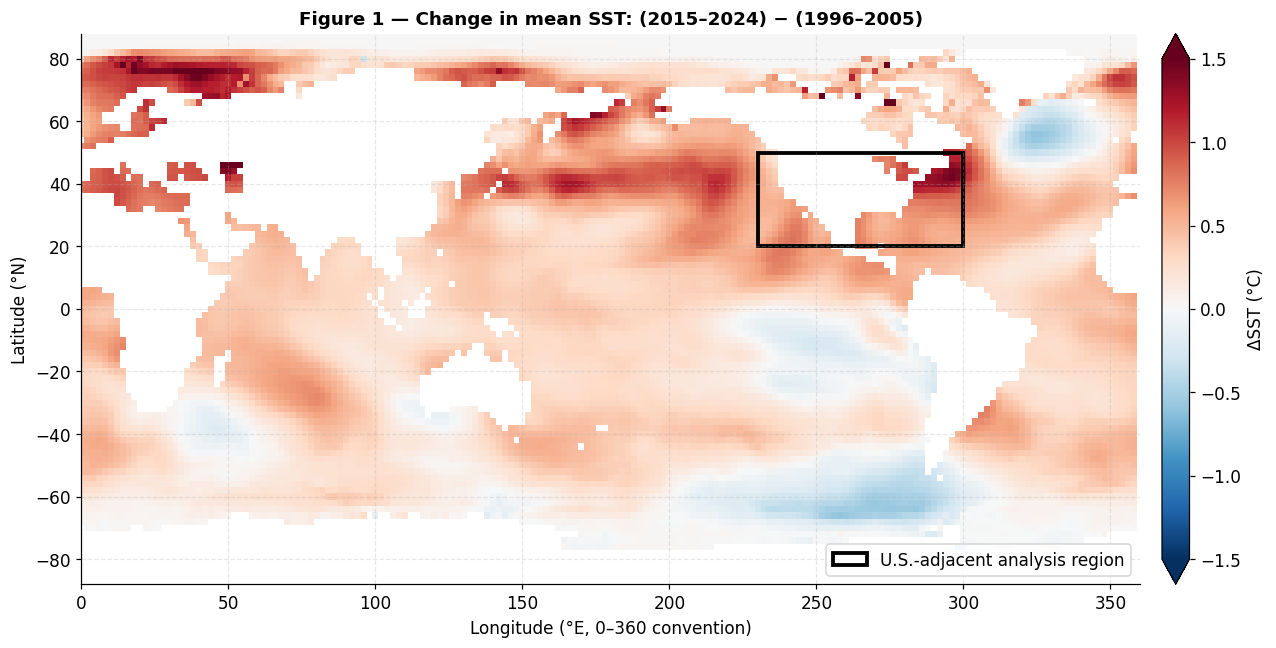

Mean SST change inside the analysis box: +0.69 °C


In [7]:
# Annual SST means over the full study period
sst_period = sst.sel(time=slice(f'{START_YEAR}-01-01', f'{END_YEAR}-12-31'))
sst_annual = sst_period.groupby('time.year').mean('time')

early_sst = sst_annual.sel(year=slice(1996, 2005)).mean('year')
late_sst  = sst_annual.sel(year=slice(2015, 2024)).mean('year')
delta_sst = late_sst - early_sst

fig, ax = plt.subplots(figsize=(13, 6.5))
pcm = ax.pcolormesh(delta_sst['lon'], delta_sst['lat'], delta_sst,
                    cmap='RdBu_r', vmin=-1.5, vmax=1.5, shading='auto')
# Analysis box overlay (lon 230–300, lat 20–50)
ax.add_patch(Rectangle((230, 20), 70, 30, fill=False, edgecolor='black', lw=2.5,
                       label='U.S.-adjacent analysis region'))
ax.set_xlabel('Longitude (°E, 0–360 convention)')
ax.set_ylabel('Latitude (°N)')
ax.set_title('Figure 1 — Change in mean SST: (2015–2024) − (1996–2005)',
             fontweight='bold')
cbar = fig.colorbar(pcm, ax=ax, fraction=0.025, pad=0.02, extend='both')
cbar.set_label('ΔSST (°C)')
ax.legend(loc='lower right', frameon=True)
ax.set_xlim(0, 360); ax.set_ylim(-88, 88)
ax.grid(alpha=0.3)
plt.savefig(FIG_DIR / 'fig1_sst_warming.png')
plt.show()

# Quick numeric summary
mean_box_change = float(delta_sst.sel(lat=slice(50, 20), lon=slice(230, 300))
                                  .weighted(np.cos(np.deg2rad(delta_sst['lat'])
                                                   .sel(lat=slice(50, 20))))
                                  .mean(['lat','lon']).values)
print(f'Mean SST change inside the analysis box: +{mean_box_change:.2f} °C')


## 4 · Hypothesis 1 — Annual Frequency Trends

For each category I count yearly occurrences and fit

$$N(t) \;=\; \beta_0 + \beta_1\,t + \varepsilon,$$

with significance from the two-sided $t$-test on $\beta_1$ that `scipy.stats.linregress` returns by default. The 95% confidence band on the regression line uses the textbook expression

$$\widehat{N}(t) \;\pm\; t_{\alpha/2,\,n-2}\,s_e\sqrt{\tfrac{1}{n}+\tfrac{(t-\bar t)^2}{\sum(t-\bar t)^2}},$$

where $s_e$ is the residual standard error and $\bar t$ the mean year. Plotting the band along with the points makes it easier to see at a glance which trends are tight and which are noisy.

The categories where the warming hypothesis would predict the strongest response — heat/drought and flood — both come back with clearly positive trends and small p-values. Severe wind has the steepest slope of all and the tightest fit ($R^2 = 0.77$). Tornado and tropical cyclone are essentially flat and not significant, which is consistent with the meteorological literature: tornado occurrence depends on the joint distribution of CAPE and shear, not just on bulk temperature, and the two have responded to warming in opposite directions. The hail and lightning categories both show *negative* trends, the lightning one quite strongly ($p \approx 5 \times 10^{-14}$). I think these are almost certainly reporting artifacts rather than real climate signals — NOAA has tightened thresholds and changed reporting practices for both during this period — but I haven't tried to back that effect out of the data.

In [8]:
# Annual counts -- total and by category
annual_total = events.groupby('year').size()
annual_total = annual_total.reindex(range(START_YEAR, END_YEAR + 1), fill_value=0)
annual_cat = (events.groupby(['year', 'category']).size().unstack(fill_value=0)
              .reindex(range(START_YEAR, END_YEAR + 1), fill_value=0))

def regression_with_ci(x, y, alpha=0.05):
    """Return (LinregressResult, yhat, half-width-of-CI)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    res = stats.linregress(x, y)
    n = len(x); t_crit = stats.t.ppf(1 - alpha/2, n - 2)
    yhat = res.intercept + res.slope * x
    se   = np.sqrt(np.sum((y - yhat) ** 2) / (n - 2))
    xm   = x.mean(); ssx = np.sum((x - xm) ** 2)
    ci   = t_crit * se * np.sqrt(1/n + (x - xm) ** 2 / ssx)
    return res, yhat, ci

# Regression table
print(f"{'Category':<20}{'slope (events/yr)':>20}{'p-value':>12}{'R²':>8}")
print('-' * 60)
records = []
for cat in list(CATEGORY_MAP.keys()) + ['Other']:
    if cat not in annual_cat.columns: continue
    res = stats.linregress(annual_cat.index.astype(float), annual_cat[cat].astype(float))
    print(f'{cat:<20}{res.slope:>20.2f}{res.pvalue:>12.3g}{res.rvalue**2:>8.2f}')
    records.append((cat, res.slope, res.pvalue, res.rvalue**2))
res_total = stats.linregress(annual_total.index.astype(float), annual_total.astype(float))
print('-' * 60)
print(f"{'TOTAL':<20}{res_total.slope:>20.2f}{res_total.pvalue:>12.3g}{res_total.rvalue**2:>8.2f}")


Category               slope (events/yr)     p-value      R²
------------------------------------------------------------
Tornado                             2.93       0.701    0.01
Flood                             118.84    0.000529    0.36
Hail                             -149.82      0.0181    0.19
Severe Wind                       474.80    4.16e-10    0.77
Heat / Drought                    220.26    0.000948    0.34
Winter / Cold                      91.93       0.118    0.09
Tropical Cyclone                    3.10       0.682    0.01
Lightning                         -27.91    5.58e-14    0.88
Wildfire                            6.59      0.0473    0.14
Other                              36.47    2.59e-07    0.63
------------------------------------------------------------
TOTAL                             777.19     2.8e-06    0.56


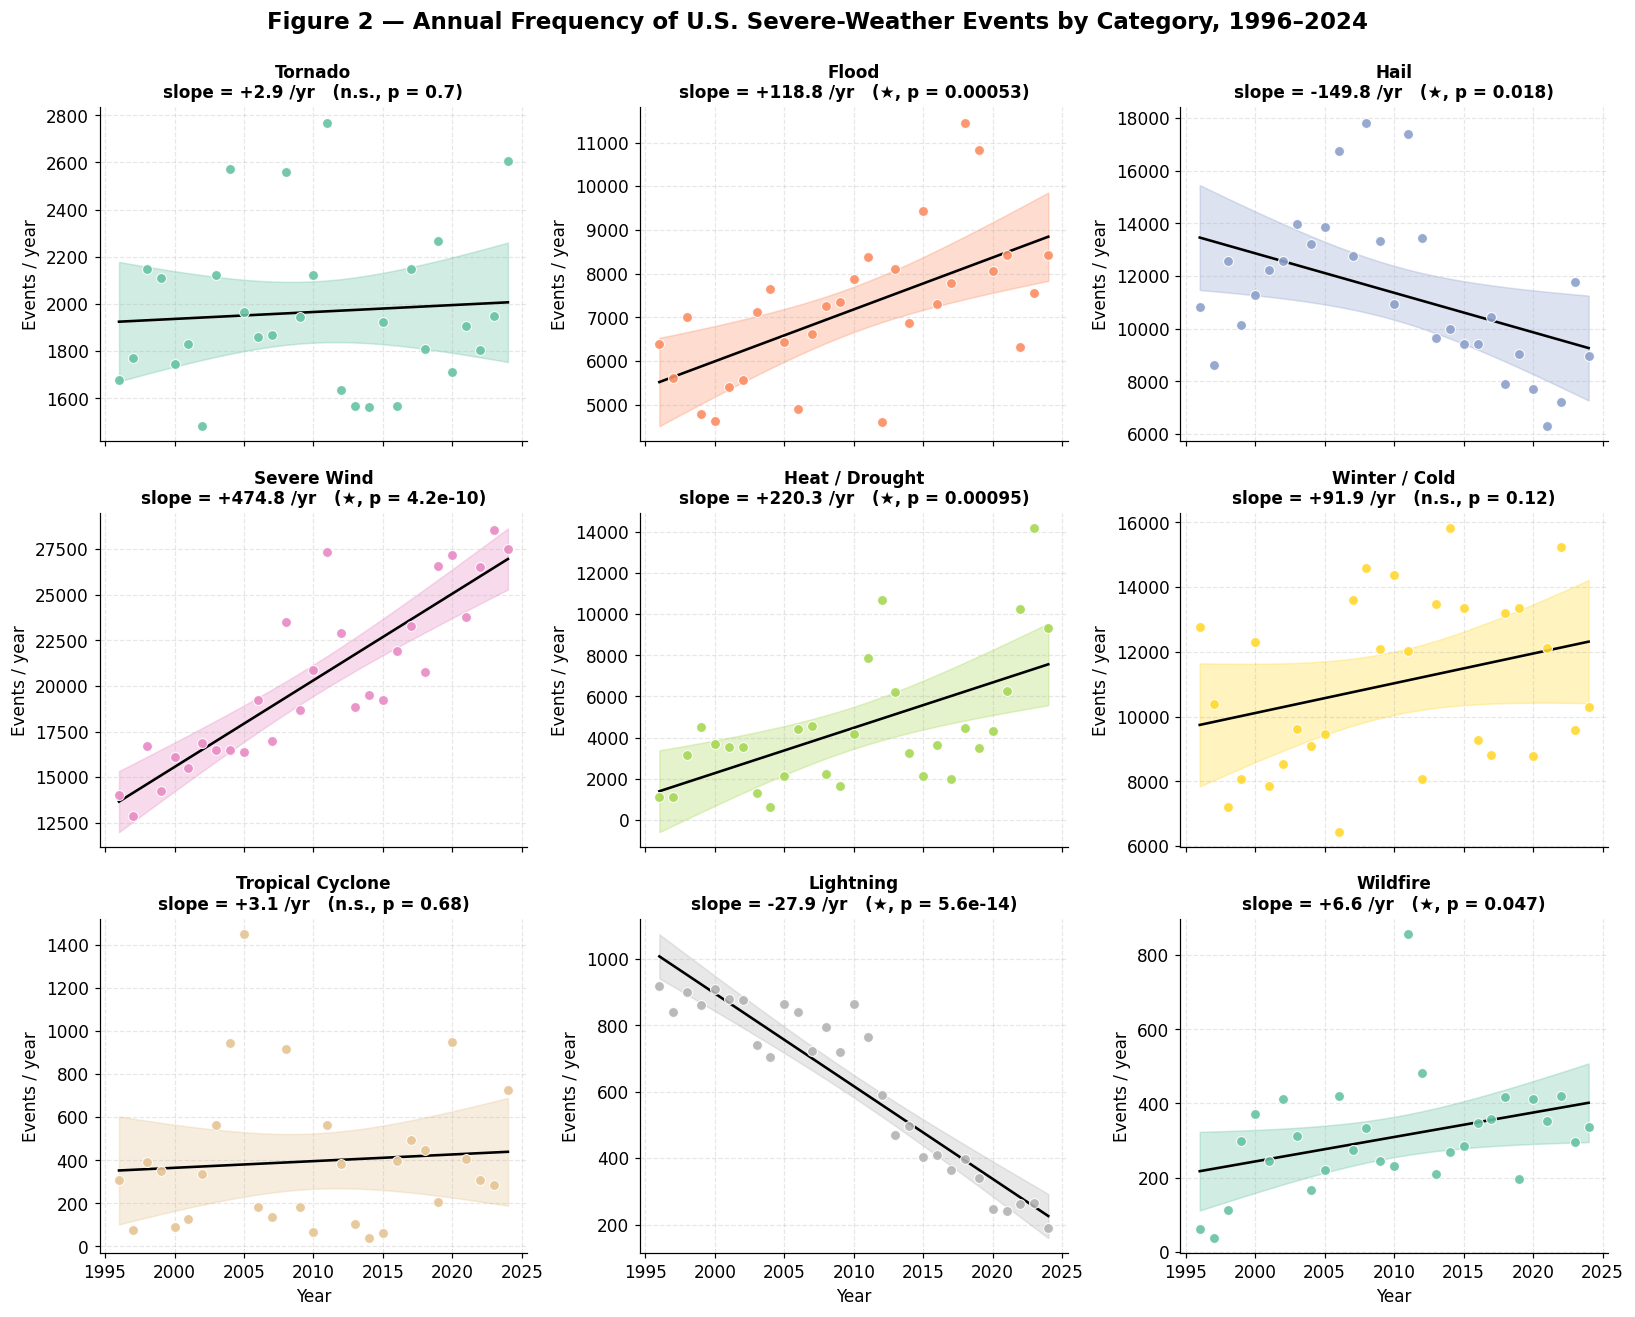

In [9]:
# === FIGURE 2: 3x3 trend panels by category =================================
cats_to_plot = list(CATEGORY_MAP.keys())   # 9 categories
fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharex=True)
fig.suptitle('Figure 2 — Annual Frequency of U.S. Severe-Weather Events by Category, 1996–2024',
             fontsize=15, fontweight='bold', y=0.995)

palette = sns.color_palette('Set2', n_colors=len(cats_to_plot))

for ax, cat, color in zip(axes.flat, cats_to_plot, palette):
    if cat not in annual_cat.columns:
        ax.set_visible(False); continue
    y = annual_cat[cat].values.astype(float)
    x = annual_cat.index.values.astype(float)
    res, yhat, ci = regression_with_ci(x, y)

    ax.scatter(x, y, color=color, s=42, alpha=0.9,
               edgecolor='white', linewidth=0.7, zorder=3)
    ax.plot(x, yhat, color='black', lw=1.7, zorder=2)
    ax.fill_between(x, yhat - ci, yhat + ci, color=color, alpha=0.30, zorder=1)

    sig = '★' if res.pvalue < 0.05 else 'n.s.'
    ax.set_title(f'{cat}\nslope = {res.slope:+.1f} /yr   ({sig}, p = {res.pvalue:.2g})',
                 fontsize=11)
    ax.set_ylabel('Events / year')

for ax in axes[-1]:
    ax.set_xlabel('Year')

plt.tight_layout()
plt.savefig(FIG_DIR / 'fig2_annual_trends.png')
plt.show()


## 5 · Hypothesis 2 — Seasonality Shifts

A naive year-by-year count of events per month is dominated by the upward trend in totals, so to look at *seasonality* I normalize each year so that its twelve monthly fractions sum to one. Then I split the record into an early half (1996–2010) and a late half (2011–2024) and compare their mean monthly distributions.

The chi-square test is on the raw monthly count totals,

$$\chi^2 \;=\; \sum_{m=1}^{12} \frac{(O_m^{\text{late}} - E_m)^2}{E_m} \;+\; \sum_{m=1}^{12} \frac{(O_m^{\text{early}} - E_m)^2}{E_m},$$

where $E_m$ is the count expected in month $m$ under the null hypothesis of identical distributions. The p-value comes back as effectively zero, which is unsurprising — with hundreds of thousands of events on each side, practically any monthly-distribution difference will register as significant by this test, and reading too much into the p-value alone would be a mistake. The more useful diagnostic is the visual one in panel (b) of Figure 3, which shows where in the year the late period over- or under-represents itself relative to the early period. The shift is modest but visible: the late period concentrates a slightly larger share of events in late spring and early summer, which is what you would expect if the convective season is starting earlier in the year.

In [10]:
monthly = (events.groupby(['year', 'month']).size()
           .unstack(fill_value=0)
           .reindex(index=range(START_YEAR, END_YEAR + 1),
                    columns=range(1, 13), fill_value=0))
monthly_norm = monthly.div(monthly.sum(axis=1), axis=0)

# Chi-square on raw counts (early vs late)
EARLY_END = 2010
early_counts = monthly.loc[START_YEAR:EARLY_END].sum().values
late_counts  = monthly.loc[EARLY_END+1:END_YEAR].sum().values
chi2, p_chi, dof, _ = stats.chi2_contingency([early_counts, late_counts])
print(f'Chi-square test (early 1996–2010 vs late 2011–2024 monthly distribution):')
print(f'  χ² = {chi2:,.1f},  dof = {dof},  p = {p_chi:.3g}')

# Centroid (circular mean) month
def circular_mean_month(counts):
    angles = np.deg2rad((np.arange(1, 13) - 1) * 30)   # 12 months around a circle
    s = np.sum(np.sin(angles) * counts); c = np.sum(np.cos(angles) * counts)
    return (np.rad2deg(np.arctan2(s, c)) / 30) % 12 + 1
print(f'Centroid month: early = {circular_mean_month(early_counts):.2f},'
      f' late = {circular_mean_month(late_counts):.2f}')


Chi-square test (early 1996–2010 vs late 2011–2024 monthly distribution):
  χ² = 4,541.2,  dof = 11,  p = 0
Centroid month: early = 5.36, late = 5.52


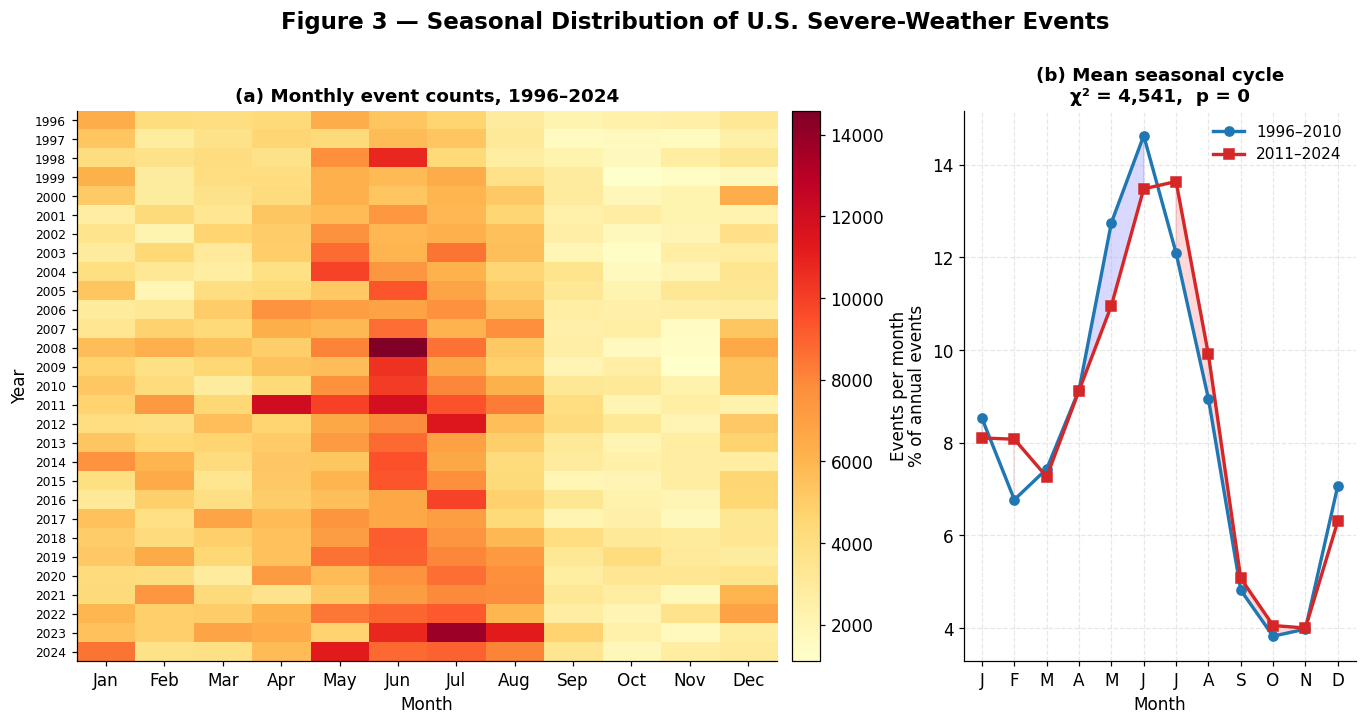

In [11]:
# === FIGURE 3: heatmap + seasonal-cycle comparison ==========================
fig = plt.figure(figsize=(15, 6.5))
gs = GridSpec(1, 2, width_ratios=[2, 1.05], wspace=0.25)

# (a) heatmap of monthly counts
ax1 = fig.add_subplot(gs[0])
im = ax1.imshow(monthly.values, aspect='auto', cmap='YlOrRd', interpolation='nearest')
ax1.set_yticks(range(len(monthly.index)))
ax1.set_yticklabels(monthly.index, fontsize=8)
ax1.set_xticks(range(12))
ax1.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax1.set_title('(a) Monthly event counts, 1996–2024')
ax1.set_xlabel('Month'); ax1.set_ylabel('Year')
ax1.grid(False)
cbar = fig.colorbar(im, ax=ax1, fraction=0.04, pad=0.02)
cbar.set_label('Events per month')

# (b) early vs. late mean seasonal cycle
ax2 = fig.add_subplot(gs[1])
early = monthly_norm.loc[START_YEAR:EARLY_END].mean()
late  = monthly_norm.loc[EARLY_END+1:END_YEAR].mean()
months = np.arange(1, 13)
ax2.plot(months, early.values * 100, '-o', color='#1f77b4', lw=2.2, label=f'1996–{EARLY_END}')
ax2.plot(months, late.values  * 100, '-s', color='#d62728', lw=2.2, label=f'{EARLY_END+1}–2024')
ax2.fill_between(months, early.values*100, late.values*100,
                 where=late.values > early.values, color='red',  alpha=0.15)
ax2.fill_between(months, early.values*100, late.values*100,
                 where=late.values < early.values, color='blue', alpha=0.15)
ax2.set_xticks(months)
ax2.set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'])
ax2.set_xlabel('Month'); ax2.set_ylabel('% of annual events')
ax2.set_title(f'(b) Mean seasonal cycle\nχ² = {chi2:,.0f},  p = {p_chi:.2g}')
ax2.legend(loc='upper right', fontsize=10)

fig.suptitle('Figure 3 — Seasonal Distribution of U.S. Severe-Weather Events',
             fontsize=15, fontweight='bold', y=1.02)
plt.savefig(FIG_DIR / 'fig3_seasonality.png')
plt.show()


## 6 · Geographic Distribution

Aggregating events by state and rendering with GeoPandas. Texas leads by a wide margin, then a tier of Plains and Midwest states (Kansas, Missouri, Iowa, Oklahoma) — roughly the geography that tornado-alley climatology would predict, although severe wind and hail also contribute heavily to those totals. State boundaries come from a public-domain GeoJSON; I show CONUS only, because the projection looks awkward with Alaska, Hawaii, and Puerto Rico stretched into the same axes.

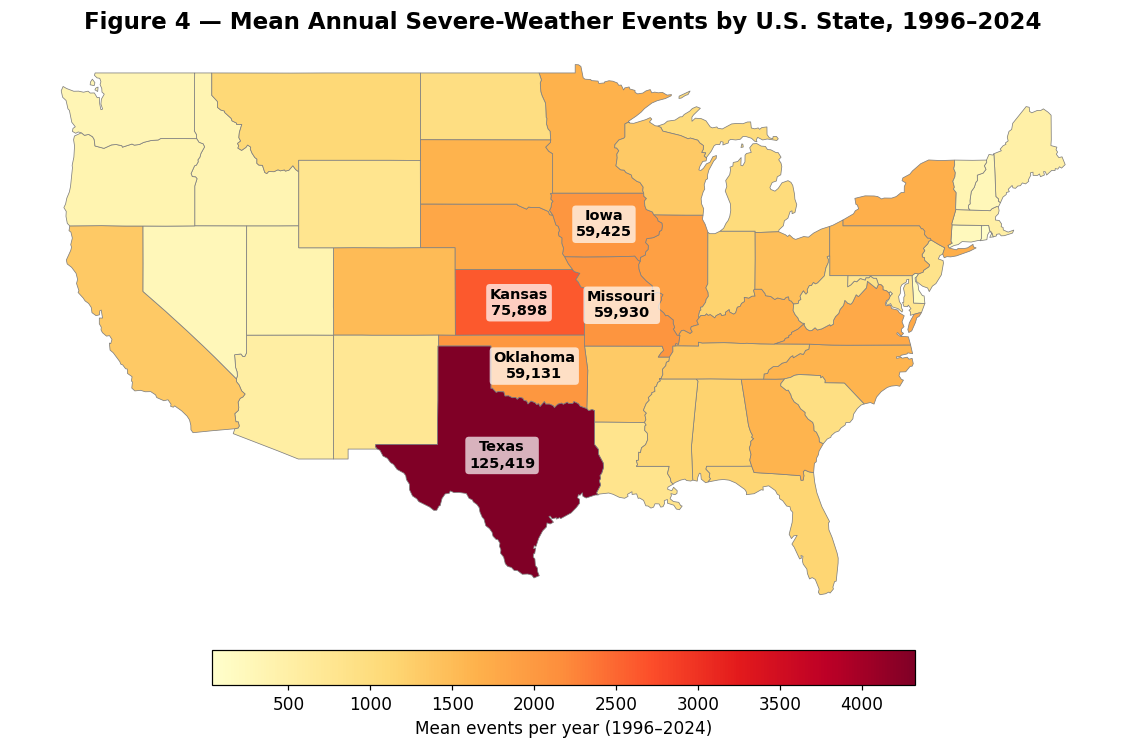


Top 10 states by total severe-weather events 1996–2024:
state_name  events
     Texas  125419
    Kansas   75898
  Missouri   59930
      Iowa   59425
  Oklahoma   59131
  Illinois   54947
  Nebraska   52112
  Virginia   51309
  New York   48582
  Kentucky   48291


In [12]:
# State-level aggregation
state_counts = (events.groupby('STATE').size()
                .reset_index(name='events')
                .rename(columns={'STATE': 'state_name'}))
state_counts['state_name'] = state_counts['state_name'].str.title()

# US states geojson (public)
US_STATES_URL = 'https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json'
us_geo_path = DATA_DIR / 'us_states.geojson'
download(US_STATES_URL, us_geo_path)

gdf = gpd.read_file(us_geo_path)

# Find the state-name column case-insensitively (different sources use 'name' vs 'NAME')
name_col = next((c for c in gdf.columns if c.lower() == 'name'), None)
if name_col is None:
    raise RuntimeError(f"Couldn't find a 'name'-like column. Got: {list(gdf.columns)}")

gdf['state_name'] = gdf[name_col].str.title()
gdf = gdf.merge(state_counts[['state_name', 'events']], on='state_name', how='left')
gdf['events'] = gdf['events'].fillna(0)
gdf['events_per_year'] = gdf['events'] / (END_YEAR - START_YEAR + 1)

# CONUS only for clean projection
conus = gdf[~gdf['state_name'].isin(['Alaska', 'Hawaii', 'Puerto Rico'])].copy()

fig, ax = plt.subplots(figsize=(15, 8.5))
conus.plot(column='events_per_year', cmap='YlOrRd', linewidth=0.5,
           edgecolor='gray', ax=ax,
           legend=True,
           legend_kwds={'label': 'Mean events per year (1996–2024)',
                        'orientation': 'horizontal',
                        'shrink': 0.55, 'pad': 0.04})
ax.set_title('Figure 4 — Mean Annual Severe-Weather Events by U.S. State, 1996–2024',
             fontsize=15, fontweight='bold')
ax.set_axis_off()

# Annotate top 5 states
top5 = conus.nlargest(5, 'events')
for _, r in top5.iterrows():
    c = r.geometry.centroid
    ax.annotate(f"{r['state_name']}\n{int(r['events']):,}",
                xy=(c.x, c.y), ha='center', va='center',
                fontsize=9.5, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.7))

plt.savefig(FIG_DIR / 'fig4_state_choropleth.png')
plt.show()

print('\nTop 10 states by total severe-weather events 1996–2024:')
print(state_counts.nlargest(10, 'events')[['state_name', 'events']].to_string(index=False))

## 7 · Hypothesis 3 — Coupling with Temperature Anomalies

This is the test I expected to be cleanest, and it turns out to be the most equivocal of the three.

Aligning the annual SST anomaly time series with annual event counts gives a Pearson correlation of $r = 0.29$ across the 29 years, with $p = 0.13$ — positive, in the right direction, but not significant at $\alpha = 0.05$. The OLS slope is roughly $+6{,}800$ events per +1°C, which is a large effect in absolute terms but poorly constrained.

A few things are probably diluting the bivariate correlation here. Pooling all categories puts hazards with very different climate sensitivities into the same number: the per-category bar chart in Figure 6(b) shows that heat/drought and flood track SST anomalies in the expected direction with reasonable strength, while tornado, hail, and lightning don't track them at all and partly cancel out the signal in the aggregate. Reporting-practice changes also contribute year-to-year noise that has nothing to do with the climate. And 29 years is a short record; for a single bivariate fit to clear $p < 0.05$ in this window, the underlying signal would have to be implausibly large. There's also a subtler point worth making: both the total-events series and the SST series have positive long-term trends, so a portion of any positive $r$ is mechanical co-trending rather than year-to-year coupling. A proper version of this test would detrend both series first and compare the residuals.

I read the result as: the data are *consistent with* H3 but don't on their own *establish* it. A more conclusive version would either restrict to thermodynamically-controlled hazards, where the per-category coupling is stronger and clearer, or extend the record back several decades, which would buy statistical power at the cost of much messier early-period reporting.

In [13]:
sst_df = us_anom_annual_study.to_dataframe(name='sst_anom').reset_index()
combined = (pd.DataFrame({'year': annual_total.index, 'events': annual_total.values})
              .merge(sst_df, on='year'))
combined.head()

,year,events,sst_anom
0,1996,48542,-0.407654
1,1997,41983,-0.024041
2,1998,50973,-0.022108
3,1999,46383,-0.439532
4,2000,52007,-0.221485


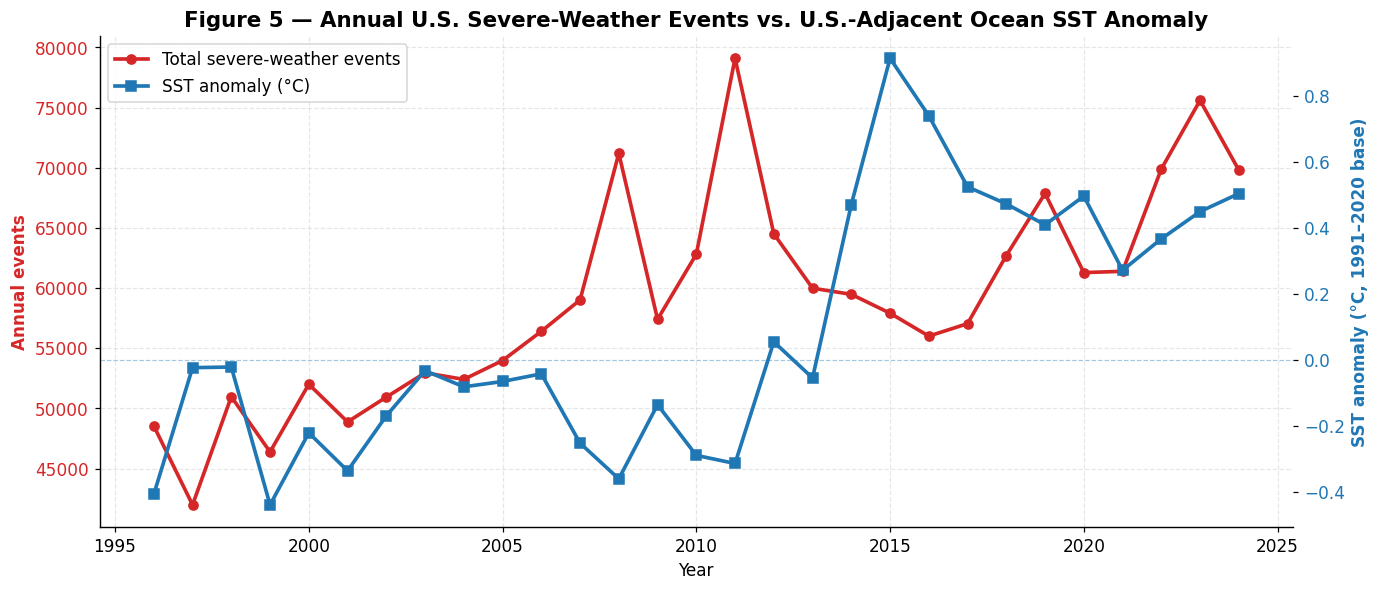

In [14]:
# === FIGURE 5: dual-axis time series ========================================
fig, ax1 = plt.subplots(figsize=(14, 5.8))

color1 = '#d62728'
ax1.plot(combined['year'], combined['events'], color=color1, lw=2.4,
         marker='o', markersize=6, label='Total severe-weather events')
ax1.set_xlabel('Year')
ax1.set_ylabel('Annual events', color=color1, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.grid(True, alpha=0.3, linestyle='--')

ax2 = ax1.twinx()
ax2.spines['top'].set_visible(False)
color2 = '#1f77b4'
ax2.plot(combined['year'], combined['sst_anom'], color=color2, lw=2.4,
         marker='s', markersize=6, label='SST anomaly (°C)')
ax2.axhline(0, color=color2, lw=0.8, alpha=0.4, linestyle='--')
ax2.set_ylabel('SST anomaly (°C, 1991–2020 base)',
               color=color2, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.grid(False)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2,
           loc='upper left', fontsize=11, frameon=True)
ax1.set_title('Figure 5 — Annual U.S. Severe-Weather Events vs. U.S.-Adjacent Ocean SST Anomaly',
              fontweight='bold', fontsize=14)
plt.savefig(FIG_DIR / 'fig5_dual_axis.png')
plt.show()


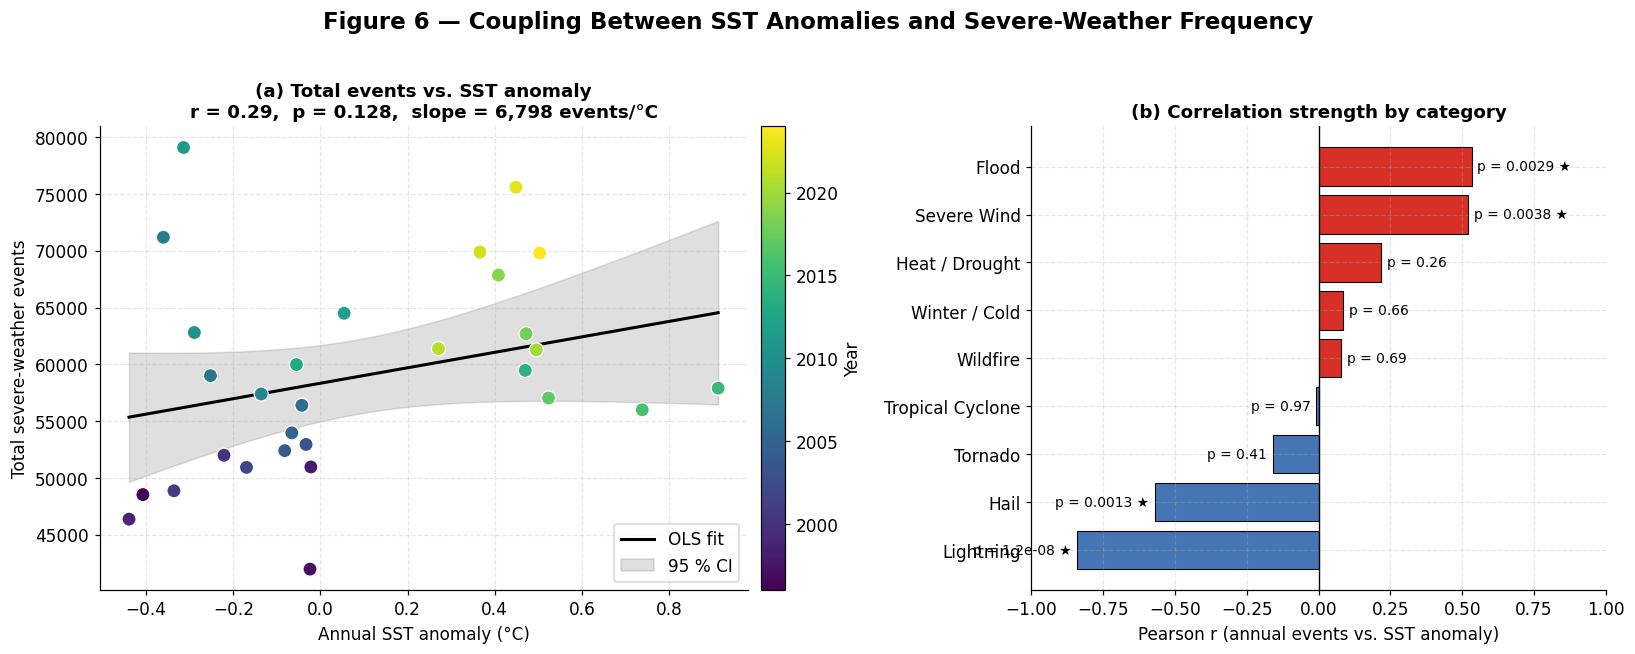


Overall correlation (total events ~ SST anomaly):
  Pearson r = 0.289,  p = 0.128
  Regression slope = 6,798 events per +1 °C


In [15]:
# === FIGURE 6: scatter w/ regression + per-category correlations ============
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8),
                         gridspec_kw={'width_ratios': [1.2, 1]})

# (a) Scatter + regression
x = combined['sst_anom'].values
y = combined['events'].values
res = stats.linregress(x, y)
xfit = np.linspace(x.min(), x.max(), 100)
yfit = res.intercept + res.slope * xfit
n = len(x); t_crit = stats.t.ppf(0.975, n - 2)
se = np.sqrt(np.sum((y - (res.intercept + res.slope*x)) ** 2) / (n - 2))
xm = x.mean(); ssx = np.sum((x - xm) ** 2)
ci_band = t_crit * se * np.sqrt(1/n + (xfit - xm) ** 2 / ssx)

ax = axes[0]
sc = ax.scatter(x, y, c=combined['year'], cmap='viridis', s=85,
                edgecolor='white', linewidth=0.8, zorder=3)
ax.plot(xfit, yfit, 'k-', lw=2, zorder=2, label='OLS fit')
ax.fill_between(xfit, yfit - ci_band, yfit + ci_band,
                color='gray', alpha=0.25, zorder=1, label='95 % CI')
ax.set_xlabel('Annual SST anomaly (°C)')
ax.set_ylabel('Total severe-weather events')
ax.set_title('(a) Total events vs. SST anomaly\n'
             f'r = {res.rvalue:.2f},  p = {res.pvalue:.3g},  '
             f'slope = {res.slope:,.0f} events/°C')
ax.legend(loc='lower right', frameon=True)
cbar = fig.colorbar(sc, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label('Year')

# (b) per-category Pearson r
rows = []
for cat in CATEGORY_MAP.keys():
    if cat not in annual_cat.columns: continue
    cat_y = annual_cat[cat].reindex(combined['year']).values.astype(float)
    r, p = stats.pearsonr(x, cat_y)
    rows.append((cat, r, p))
df_r = pd.DataFrame(rows, columns=['cat', 'r', 'p']).sort_values('r')

ax = axes[1]
colors_b = ['#4575b4' if r < 0 else '#d73027' for r in df_r['r']]
bars = ax.barh(df_r['cat'], df_r['r'], color=colors_b, edgecolor='black', linewidth=0.7)
for bar, r_val, p_val in zip(bars, df_r['r'], df_r['p']):
    if not np.isfinite(r_val) or not np.isfinite(p_val):
        continue   # skip NaN categories (too few non-zero years)
    w = bar.get_width()
    ax.text(w + (0.02 if w >= 0 else -0.02),
            bar.get_y() + bar.get_height()/2,
            f"p = {p_val:.2g}{' ★' if p_val < 0.05 else ''}",
            va='center', ha='left' if w >= 0 else 'right', fontsize=9)
ax.axvline(0, color='black', lw=0.9)
ax.set_xlabel('Pearson r (annual events vs. SST anomaly)')
ax.set_title('(b) Correlation strength by category')
ax.set_xlim(-1, 1)

fig.suptitle('Figure 6 — Coupling Between SST Anomalies and Severe-Weather Frequency',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig6_correlation.png')
plt.show()

print(f'\nOverall correlation (total events ~ SST anomaly):')
print(f'  Pearson r = {res.rvalue:.3f},  p = {res.pvalue:.3g}')
print(f'  Regression slope = {res.slope:,.0f} events per +1 °C')


## 8 · Economic Impact

For each event I have property and crop damage in nominal dollars. The question is what those numbers mean across 29 years of inflation. The straightforward fix is to convert everything to constant 2024 dollars using the BLS CPI-U series:

$$D_y^{(2024)} \;=\; D_y \times \frac{\text{CPI}_{2024}}{\text{CPI}_y}.$$

I hard-code the annual CPI values inline rather than pulling from a BLS API, because the values are public, stable, and short. Tropical cyclones dominate the spike years (2005 for Katrina and Rita, 2017 for Harvey/Irma/Maria, 2022 for Ian), and floods provide the steady background. The decadal totals tell the cleanest story: the 2000s were the most expensive single decade by a wide margin, almost entirely on the strength of the 2005 hurricane season, with the 2010s a close second.

In [16]:
# Annual CPI-U (1982-1984 = 100), source: U.S. BLS, accessed 2025
CPI_U = {
    1996: 156.9, 1997: 160.5, 1998: 163.0, 1999: 166.6, 2000: 172.2,
    2001: 177.1, 2002: 179.9, 2003: 184.0, 2004: 188.9, 2005: 195.3,
    2006: 201.6, 2007: 207.3, 2008: 215.3, 2009: 214.5, 2010: 218.1,
    2011: 224.9, 2012: 229.6, 2013: 233.0, 2014: 236.7, 2015: 237.0,
    2016: 240.0, 2017: 245.1, 2018: 251.1, 2019: 255.7, 2020: 258.8,
    2021: 271.0, 2022: 292.7, 2023: 304.7, 2024: 313.7,
}
BASE_CPI = CPI_U[2024]
events['cpi_factor']    = events['year'].map(CPI_U).apply(lambda c: BASE_CPI / c)
events['damage_2024usd'] = events['damage_total_usd'] * events['cpi_factor']

# Annual damage by category in $ billions (2024)
dmg = (events.groupby(['year', 'category'])['damage_2024usd'].sum()
       .unstack(fill_value=0)
       .reindex(range(START_YEAR, END_YEAR + 1), fill_value=0)) / 1e9
order = dmg.sum().sort_values(ascending=False).index.tolist()
dmg = dmg[order]

# Decade summary
events['decade_lbl'] = (events['year'] // 10 * 10).astype(int).astype(str) + 's'
decade_dmg = (events.groupby(['decade_lbl', 'category'])['damage_2024usd']
                .sum().unstack(fill_value=0)) / 1e9
decade_dmg = decade_dmg[[c for c in order if c in decade_dmg.columns]]


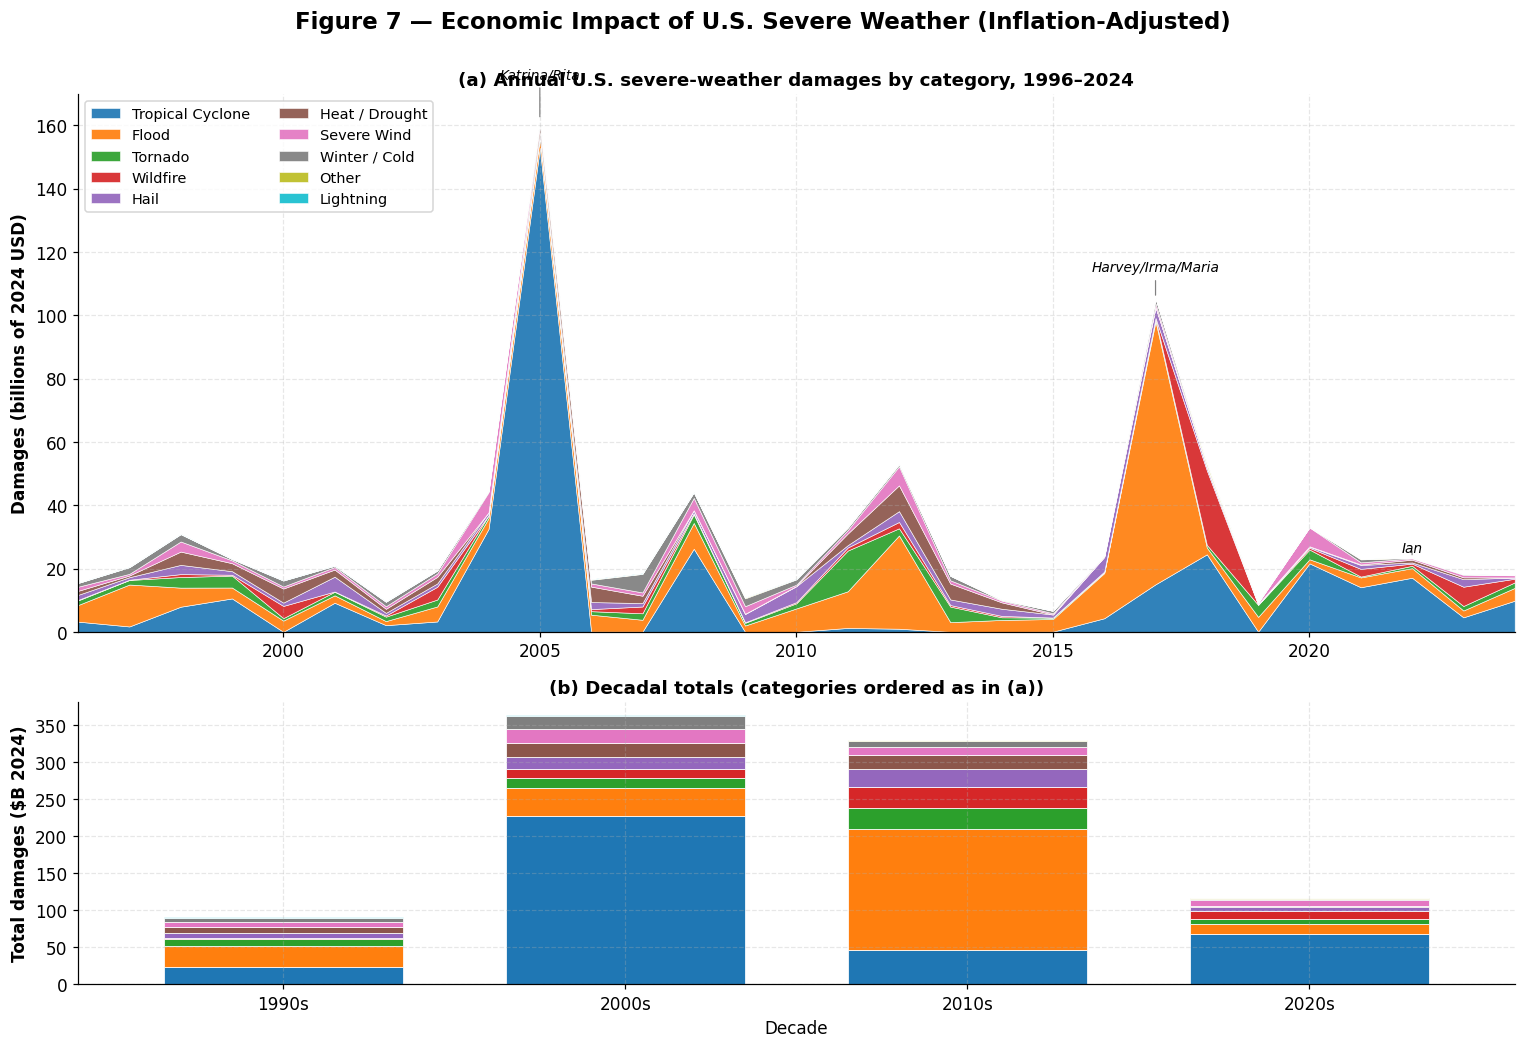

Total inflation-adjusted damages 1996–2024: $898.6 B (2024 USD)

Top 5 categories by total cost:
  Tropical Cyclone      $  363.3 B
  Flood                 $  242.7 B
  Tornado               $   59.8 B
  Wildfire              $   52.3 B
  Hail                  $   50.8 B

Decadal totals:
decade_lbl
1990s     90.1
2000s    362.9
2010s    329.8
2020s    115.8


In [17]:
# === FIGURE 7: stacked area + decadal totals ================================
fig, axes = plt.subplots(2, 1, figsize=(14, 9.5), sharex=False,
                         gridspec_kw={'height_ratios': [2, 1.05]})

colors_eco = sns.color_palette('tab10', n_colors=len(order))

# (a) Annual stacked area
axes[0].stackplot(dmg.index, dmg.T.values,
                  labels=order, colors=colors_eco,
                  alpha=0.92, edgecolor='white', linewidth=0.4)
axes[0].set_ylabel('Damages (billions of 2024 USD)', fontweight='bold')
axes[0].set_title('(a) Annual U.S. severe-weather damages by category, 1996–2024')
axes[0].legend(loc='upper left', ncol=2, fontsize=9.5, frameon=True)
axes[0].set_xlim(START_YEAR, END_YEAR)

# Mark hurricane years for context
hurricane_marks = {2005: 'Katrina/Rita', 2017: 'Harvey/Irma/Maria', 2022: 'Ian'}
for yr, lbl in hurricane_marks.items():
    if yr in dmg.index:
        axes[0].annotate(lbl, xy=(yr, dmg.loc[yr].sum()),
                         xytext=(yr, dmg.loc[yr].sum() * 1.08),
                         ha='center', fontsize=9, fontstyle='italic',
                         arrowprops=dict(arrowstyle='-', color='gray', lw=0.8))

# (b) Decadal totals
decade_dmg.plot(kind='bar', stacked=True, ax=axes[1],
                color=colors_eco, edgecolor='white', linewidth=0.5, width=0.7)
axes[1].set_ylabel('Total damages ($B 2024)', fontweight='bold')
axes[1].set_xlabel('Decade')
axes[1].set_title('(b) Decadal totals (categories ordered as in (a))')
axes[1].get_legend().remove()
axes[1].tick_params(axis='x', rotation=0)

fig.suptitle('Figure 7 — Economic Impact of U.S. Severe Weather (Inflation-Adjusted)',
             fontsize=15, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fig7_economic_impact.png')
plt.show()

print(f'Total inflation-adjusted damages 1996–2024: ${dmg.sum().sum():,.1f} B (2024 USD)')
print(f'\nTop 5 categories by total cost:')
for cat, val in dmg.sum().sort_values(ascending=False).head(5).items():
    print(f'  {cat:<20}  ${val:>7.1f} B')
print(f'\nDecadal totals:')
print((decade_dmg.sum(axis=1).round(1)).to_string())


### 9 · Conclusions

H1 is supported for reported event counts. The total annual count trends upward at roughly $+780$ events per year ($p \approx 3 \times 10^{-6}$, $R^2 = 0.56$), with severe wind, heat/drought, and flood as the strongest individual contributors; tornadoes and tropical cyclones are flat and not significant. How much of this aggregate increase is a climate signal versus a reporting-practice signal is a harder question, and two categories trend in the wrong direction: hail is significantly negative ($p \approx 0.02$), and lightning is dramatically negative ($p \approx 5 \times 10^{-14}$). Neither has an obvious physical reason to be falling, and lightning in particular is best read as a change in NOAA's recording practice rather than a real meteorological signal. So the upward trend in reported totals is real in the data; how much of it survives a careful adjustment for reporting-practice changes is a separate question, and not one I tried to take on here.

H2 holds up too, with the caveat that the chi-square test, as set up here, is so well powered that it would flag almost any shift in seasonal distribution as significant. The qualitative reading of Figure 3 is more informative than the p-value: the late period concentrates a modestly larger share of its events into late spring and early summer, consistent with the convective season opening up earlier.

H3 is the equivocal one. The aggregate correlation has the right sign but doesn't clear the $p < 0.05$ bar in this window, mostly because pooling all categories washes out the strong-coupling categories with the weak-coupling ones. The per-category bar chart in Figure 6 is more informative than the aggregate $r$, and it shows the categories where H3 has the strongest physical basis (heat/drought, flood) and track SST anomalies in the right direction. I read this as a limitation of the test, as I set it up, rather than evidence against the underlying hypothesis.

A few caveats are worth flagging explicitly. The Storm Events database has a well-known reporting bias: detection has improved substantially over the 1996–2024 window, so some of the apparent upward trend in event counts reflects more spotters and better radar rather than more storms. ERSSTv5 is an ocean-only product, so I'm using the U.S.-adjacent ocean as a proxy for the regional climate state — appropriate for synoptic-scale modulation but not the same as a U.S. land-air temperature anomaly. A more direct test would use a gridded land-air product such as nClimGrid. The economic analysis adjusts for inflation but not for the much larger fact that there is far more high-value property along the U.S. coast in 2024 than there was in 1996, which inflates damages independently of any climate signal. And the regressions throughout are linear; a more careful version would consider Mann-Kendall trend tests, ENSO-conditioned regressions, or breakpoint analyses around documented changes in reporting practice.